In [1]:
import sys
sys.path.append('/home/ofir/ofir_code/crystoper')
from glob import glob

import pandas as  pd
import ast
from os.path import join
from tqdm import tqdm 
import matplotlib.pyplot as plt
import seaborn as sns 
from crystoper.trainer import load_train_and_val_loss_from_logs_folder, load_log

/home/ofir/.pyenv/versions/3.10.13/envs/crystoEnv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
logs_folder = '/home/ofir/ofir_code/crystoper/logs'


In [3]:
train_loss, val_loss, summary = load_train_and_val_loss_from_logs_folder(logs_folder)

train loss over epochs was: 
    epoch  train_loss  val_loss
0       1    0.012215  0.012066
1       2    0.011905  0.011977
2       3    0.011871  0.011950
3       4    0.011848  0.011928
4       5    0.011829  0.011913
5       6    0.011749  0.011831
6       7    0.011737  0.011822
7       8    0.011727  0.011817
8       9    0.011723  0.011813
9      10    0.011720  0.011815
10     11    0.011713  0.011806
11     12    0.011709  0.011806
12     13    0.011706  0.011801
13     14    0.011698  0.011802
14     15    0.011696  0.011796
15     16    0.011691  0.011796
16     17    0.011687  0.011796
17     18    0.011702  0.011799
18     19    0.011678  0.011789
19     20    0.011677  0.011790
20     21    0.011672  0.011787
21     22    0.011669  0.011781
22     23    0.011664  0.011785
23     24    0.011661  0.011783
24     25    0.011656  0.011785
25     26    0.011655  0.011781
26     27    0.011651  0.011777
27     28    0.011650  0.011776
28     29    0.011645  0.011778
29     30  

Text(0, 0.5, 'loss')

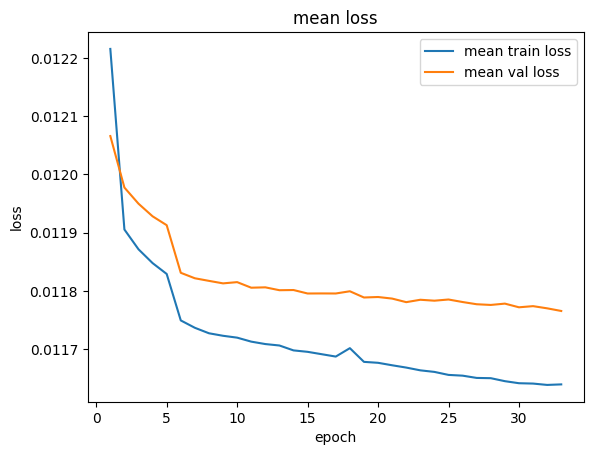

In [4]:
fig, ax = plt.subplots()
ax.plot(summary.epoch, summary.train_loss, label='mean train loss')
ax.plot(summary.epoch, summary.val_loss, label='mean val loss')

ax.set_title('mean loss')
plt.legend()

ax.set_xlabel('epoch')
ax.set_ylabel('loss')

In [ ]:
for path in glob(logs_folder + '/*.txt'):
    print(path)

/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e6.txt
/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e5.txt
/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e2.txt
/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e1.txt
/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e4.txt
/home/ofir/ofir_code/crystoper/logs/esmccomplex_singles_113K_e3.txt


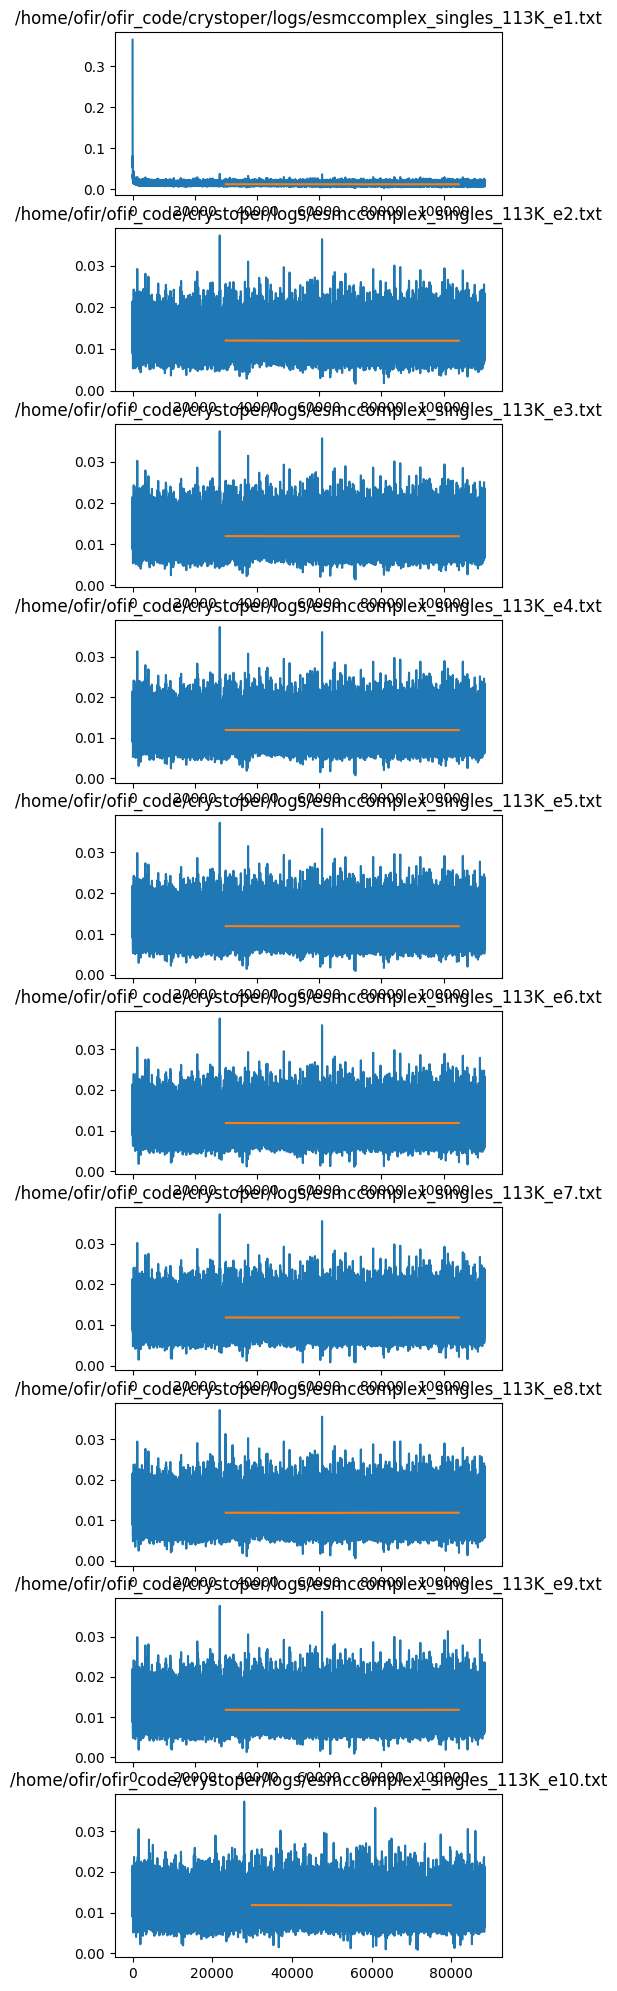

In [72]:
paths = list(glob(logs_folder + '/*.txt'))
paths = sorted(paths, key=lambda x: int(x.split('_e')[-1][:-4]))

fig, axes = plt.subplots(len(paths), 1, figsize=[5,25])

for ax, path in zip(axes,paths):
    log = load_log(path)
    df = log['train_loss']
    ax.plot(df.i, df.train_loss, label='train_loss')
    
    df = log['val_loss']
    ax.plot(df.i, df.val_loss, label='val_loss')
    
    ax.set_title(path)
    
    

In [52]:
log = load_log(path)

In [64]:
log['val_loss']

,epoch,batch,i,train_loss,val_loss,true_sent,pred_sent
14984,None,14978,29956,NaN,0.011918,None,"0.1.2.1:1.3:1,0.2,0,0-0.5,0:1:9,0;0.6,0(0.9)0...."


,epoch,train_loss,val_loss
0,5,0.011757,0.011835
1,6,0.011873,0.011947
2,7,0.011770,0.011848
3,8,0.011767,0.011847
4,9,0.011754,0.011834
5,10,0.011744,0.011831
6,11,0.011681,0.011771
7,12,0.011674,0.011762
8,13,0.011670,0.011758
9,14,0.011664,0.011754


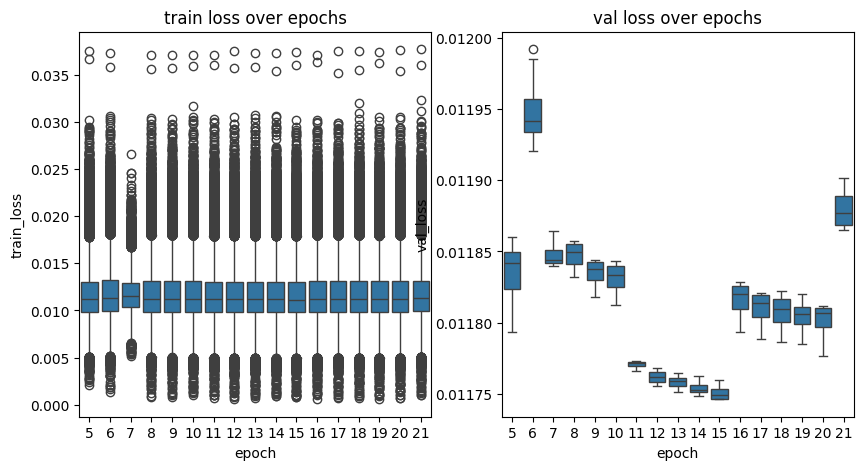

In [11]:
#plot boxplot of loss
import seaborn as sns

fig, axes = plt.subplots(1,2, figsize=[10,5])
sns.boxplot(x="epoch", y="train_loss", data=train_loss, ax=axes[0])
df1 = train_loss.groupby('epoch')['train_loss'].mean()

axes[0].set_title('train loss over epochs')
axes[1].set_title('val loss over epochs')

sns.boxplot(x="epoch", y="val_loss", data=val_loss, ax=axes[1])
train_loss.groupby('epoch')['val_loss'].mean()
df2 = val_loss.groupby('epoch')['val_loss'].mean()

axes[0].set_title('train loss over epochs')
axes[1].set_title('val loss over epochs')

pd.concat([df1, df2], axis=1).reset_index()

# CHECK CHECKPOINT

In [5]:
REPO_FOLDER = '..'

import sys
sys.path.append(REPO_FOLDER) 

import argparse
from os.path import join
from pathlib import Path
import re 
import pandas as pd
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import EsmTokenizer, BartTokenizer, BartModel, BartForConditionalGeneration
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

from crystoper import config
from crystoper.processor import filter_by_pdbx_details_length, filter_for_single_entities
from crystoper.utils.general import vprint, make_parent_dirs
from crystoper.esmc_models import ESMCcomplex
from crystoper.trainer import ESMCTrainer, seq2sent, train_model
from crystoper.dataset import  Sequence2BartDataset



device = 'cpu'

In [6]:
esm_model = ESMCcomplex()
esm_tokenizer = EsmTokenizer.from_pretrained("facebook/esm2_t33_650M_UR50D")    
bart_tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')
bart_model = BartForConditionalGeneration.from_pretrained('facebook/bart-base') 
data_path = join(REPO_FOLDER, config.toy_path)
vectors_path = join(REPO_FOLDER, config.details_vectors_path, 'toy', 'bart_vectors_0.pkl')


In [8]:
checkpoint_path = '/home/ofir/ofir_code/crystoper/checkpoints/esmccomplex_singles_113K_e32/esmccomplex_singles_113K_e32.pth'
checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))
esm_model.load_state_dict(checkpoint['model_state_dict'], strict=False)
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
loss_fn = checkpoint['loss_fn']
prev_epoch = checkpoint['epoch']
session_name = checkpoint['session_name']

/tmp/ipykernel_14347/3677871730.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))


: 

In [ ]:
# We will first perform inference using the untrained model 
data = pd.read_csv(data_path)

X = data['sequence']
Y_true = data['pdbx_details'] 

bart_model.to(device)
esm_model.to(device)

print(f'\n\nStarting inference of {len(data)} instances!')

for x, y_true in tqdm(zip(X,Y_true)):
    pred = seq2sent(x, esm_model, esm_tokenizer, bart_model, bart_tokenizer, ac=True)
    y_true = y_true.replace("\n", " ")
    print(f'True sentence: {y_true}')
    print(f'Pred sentence: {pred}')
    print('\n\n')